# *B. cereus* group: local recombination and mutation rates, and hotspots

This notebook repeats the *Bacillus cereus* group analysis of the paper (Section 3.2):

1. load the observed summary statistics of 1,277 alignment blocks of 13 genomes;
2. train NPE on 50,000 ClonalOrigin simulations on the *B. cereus* clonal genealogy;
3. sample the posterior of $(\rho_s, \theta_s, \ell)$ for every block;
4. detect recombination and mutation hotspots with the ppDoG detector.

Run it from the `examples` folder.
The trained posterior is saved in `data/`, and later runs load it instead of training again.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from bacnpe.summary_stats import STAT_NAMES
from bacnpe.npe import LeaveLengthOut_NN, train_npe, save_npe, load_npe, sample_posteriors
from bacnpe.detection import detect_hotspots, save_hotspot_tables

warnings.filterwarnings("ignore", category=UserWarning)

DATA = Path("data")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

c:\Users\u2008181\bacnpe\.bacnpe_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load observed data

One row per alignment block. Positions refer to the reference genome *B. anthracis* Ames 0581.

In [2]:
x_obs_info_table = pd.read_csv(DATA / "bacillus_block_info.csv", index_col=0)
x_obs_info_table.head()

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_raw,Start_pos_raw,End_pos_raw
Gene_ID,,,,,,,
0_0,5247,71581,76827,True,5264,71581,76844
0_1,5246,76828,82073,True,5247,76845,82091
1,4191,67350,71540,True,4197,67350,71546
2,2175,28543,30717,True,2182,28543,30724
3,2401,142577,144977,True,2434,142577,145010


The observed statistics for each alignment block.

In [3]:
x_obs = np.loadtxt(DATA / "bacillus_block_summary_stats.csv", delimiter=",")
print(x_obs.shape)
print("Lengths match the block table:", np.allclose(x_obs[:, -1], x_obs_info_table["Gene_Length"]))
pd.DataFrame(x_obs, columns=STAT_NAMES).head()

(1277, 30)
Lengths match the block table: True


,D_near_sum,D_far_sum,D_prime_near_sum,D_prime_far_sum,r2_near_sum,r2_far_sum,g4_near_sum,g4_far_sum,D_near_mean,D_far_mean,...,wakeley_pi2,tajima_D,wall_B,wall_Q,hudson_Rm,kelly_ZnS,r2_decay_a,r2_decay_b,r2_decay_c,L
0,15419.721893,4704.781065,272662.338442,87426.172131,72591.286620,22300.938191,24487.0,8459.0,0.053457,0.050561,...,29710.928994,-0.509121,0.116838,0.132723,176.0,0.248734,8.729313,5.389339e-07,-8.472210,5247.0
1,14843.786982,5049.887574,207586.848009,75435.031097,58864.231354,19092.684728,18813.0,8166.0,0.067523,0.062446,...,25782.463511,0.106838,0.121290,0.134021,156.0,0.259251,0.000000,0.000000e+00,0.000000,5246.0
2,5067.017751,2195.911243,77302.883977,33134.998390,21435.003498,8880.691486,7241.0,4036.0,0.061721,0.061409,...,9914.019066,-0.101128,0.127835,0.150206,88.0,0.257229,0.115962,3.887849e-01,0.258507,4191.0
3,350.289941,77.893491,5703.592754,1389.212083,1485.817925,306.386346,506.0,167.0,0.058130,0.052738,...,551.297173,-0.176730,0.155738,0.203252,25.0,0.238865,0.099604,6.558800e-03,0.201158,2175.0
4,4837.704142,1513.443787,68300.151252,21486.768947,21406.159912,6991.886711,3668.0,981.0,0.068532,0.068559,...,9837.980276,-0.075479,0.158140,0.174014,59.0,0.306459,0.024694,6.377722e-01,0.308675,2401.0


### Delete observations with no signal

Blocks without segregating sites carry almost no information about the rates, and blocks
longer than 10,000 bp are outside the prior on $\ell$. (There are none of either in this dataset.)

In [4]:
no_signal = x_obs[:, STAT_NAMES.index("prop_segregating_sites")] == 0
too_long = x_obs_info_table["Gene_Length"].to_numpy() > 10_000
keep = ~(no_signal | too_long)
print(f"No signal: {no_signal.sum()}, too long: {too_long.sum()}, kept: {keep.sum()} of {len(keep)}")

x_obs = x_obs[keep]
gene_info = x_obs_info_table[keep]

No signal: 0, too long: 0, kept: 1277 of 1277


## Load simulation data

50,000 simulations on the *B. cereus* clonal genealogy with $\delta = 236$ bp, using the priors
$\rho_s \sim U(0, 0.2)$, $\theta_s \sim U(0, 0.1)$ and $\ell \sim$ DiscreteUniform $\{100, \dots, 10000\}$.
`bacillus_theta.csv` holds the parameters $(\rho_s, \theta_s, \ell)$ and `bacillus_x.csv` the 30 statistics,
row by row. They can be generated with `bacnpe.parallel_sim` (see `01_simulate.py`).

In [5]:
theta = np.loadtxt(DATA / "bacillus_theta.csv", delimiter=",")
x = np.loadtxt(DATA / "bacillus_x.csv", delimiter=",")
print(theta.shape, x.shape)
print("Parameter ranges:", theta.min(axis=0), theta.max(axis=0))

(50000, 3) (50000, 30)
Parameter ranges: [1.52468683e-05 2.89082527e-06 1.00000000e+02] [1.99991688e-01 9.99881849e-02 1.00000000e+04]


## NPE

### Using all simulations

The configuration selected in the paper (Table S3):

- compression network: one hidden layer of 128 units, 2 learned features plus $\ell$;
- neural spline flow: 8 transforms, 30 hidden features, 5 bins;
- training: learning rate $10^{-4}$, batch size 100, early stopping after 20 epochs without improvement.

Simulations with NaN statistics are dropped before training.

In [6]:
seed = 100
save_path = DATA / "bacillus_trained_npe.pt"

if save_path.exists():
    posterior = load_npe(save_path)["posterior"]
else:
    torch.manual_seed(seed)
    embedding_net = LeaveLengthOut_NN(input_dim=30, num_hiddens=128, num_hidden_layers=1, num_outputs=2)
    result = train_npe(
        theta, x,
        seed=seed,
        embedding_net=embedding_net,
        model="nsf", hidden_features=30, num_transforms=8, num_bins=5,
        training_batch_size=100, learning_rate=1e-4,
        max_num_epochs=500, stop_after_epochs=20, clip_max_norm=None,
    )
    print(f"Dropped {result.settings['n_dropped']} simulations with NaN/inf statistics")
    save_npe(result, save_path)
    posterior = result.posterior

### Training and validation loss

Only available right after training (not when the posterior was loaded from file).

In [7]:
if "result" in globals():
    summary = result.inference.summary
    plt.figure(figsize=(8, 4))
    plt.plot(summary["training_loss"], label="Training loss")
    plt.plot(summary["validation_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.show()

### Plug in observation data to get posterior

`theta_post[g, m]` is posterior draw $m$ of $(\rho_s, \theta_s, \ell)$ for block $g$.

In [8]:
num_posterior_samples = 1000
theta_post = sample_posteriors(posterior, x_obs, num_samples=num_posterior_samples, seed=seed)
theta_post.shape

Sampling posteriors: 100%|██████████| 1277/1277 [00:46<00:00, 27.67it/s]


(1277, 1000, 3)

As a check of the inference (Figure S5 of the paper), the inferred block lengths should match the observed ones.

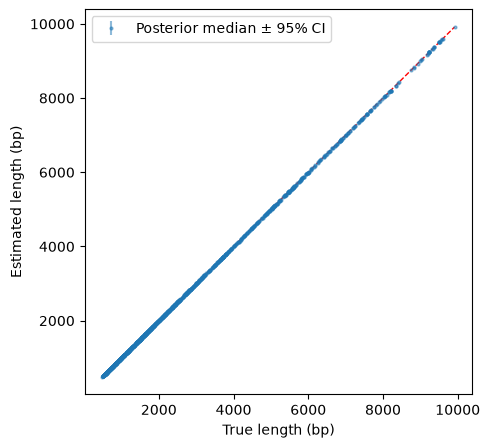

In [9]:
L_obs = x_obs[:, -1]
L_q = np.quantile(theta_post[:, :, 2], [0.025, 0.5, 0.975], axis=1)

plt.figure(figsize=(5, 5))
plt.errorbar(L_obs, L_q[1], yerr=[L_q[1] - L_q[0], L_q[2] - L_q[1]], fmt="o", ms=2, alpha=0.5,
             label="Posterior median ± 95% CI")
plt.plot([L_obs.min(), L_obs.max()], [L_obs.min(), L_obs.max()], "r--", lw=1)
plt.xlabel("True length (bp)")
plt.ylabel("Estimated length (bp)")
plt.legend()
plt.show()

## Detect hotspots

ppDoG settings of the paper for *B. cereus* (Table S1): narrow bandwidth 10 kb, broad bandwidth 1 Mb,
$\tau = 0.2$, probability threshold 0.9, and minimum fold enrichment 1.5 for both recombination
and mutation. Blocks are placed at their start positions on the 5,227,440 bp chromosome.

In [10]:
gene_starts = gene_info["Start_pos_raw"].to_numpy()
gene_ends = gene_info["End_pos_raw"].to_numpy()
chromosome_length_bp = 5_227_440

settings = dict(
    gene_ends=gene_ends,
    narrow_bandwidth_bp=10_000,
    broad_bandwidth_bp=1_000_000,
    probability_threshold=0.90,
    residual_log_sd=0.20,
    random_state=10,
    max_gap_bp=800_000,
)

### Recombination hotspots

Detected hotspot segments:
  0.60-0.63 Mb; 16 genes; peak P=1.000; peak enrichment=2.31x
  0.64-0.67 Mb; 9 genes; peak P=1.000; peak enrichment=3.04x
  0.82-0.83 Mb; 6 genes; peak P=0.968; peak enrichment=1.72x
  0.87-0.88 Mb; 3 genes; peak P=0.924; peak enrichment=1.70x
  0.92-1.03 Mb; 25 genes; peak P=1.000; peak enrichment=5.49x
  1.07-1.07 Mb; 3 genes; peak P=0.907; peak enrichment=1.72x
  1.79-1.81 Mb; 9 genes; peak P=0.976; peak enrichment=1.78x
  2.80-2.85 Mb; 19 genes; peak P=1.000; peak enrichment=2.46x
  2.91-3.01 Mb; 19 genes; peak P=1.000; peak enrichment=4.64x
  3.11-3.12 Mb; 8 genes; peak P=1.000; peak enrichment=2.97x
  3.15-3.24 Mb; 19 genes; peak P=0.998; peak enrichment=2.32x
  4.33-4.35 Mb; 7 genes; peak P=1.000; peak enrichment=1.99x
  4.46-4.46 Mb; 2 genes; peak P=0.919; peak enrichment=1.69x
  4.52-4.56 Mb; 12 genes; peak P=1.000; peak enrichment=2.34x
  4.57-4.63 Mb; 21 genes; peak P=1.000; peak enrichment=2.60x
  4.70-4.76 Mb; 18 genes; peak P=0.999; peak enrich

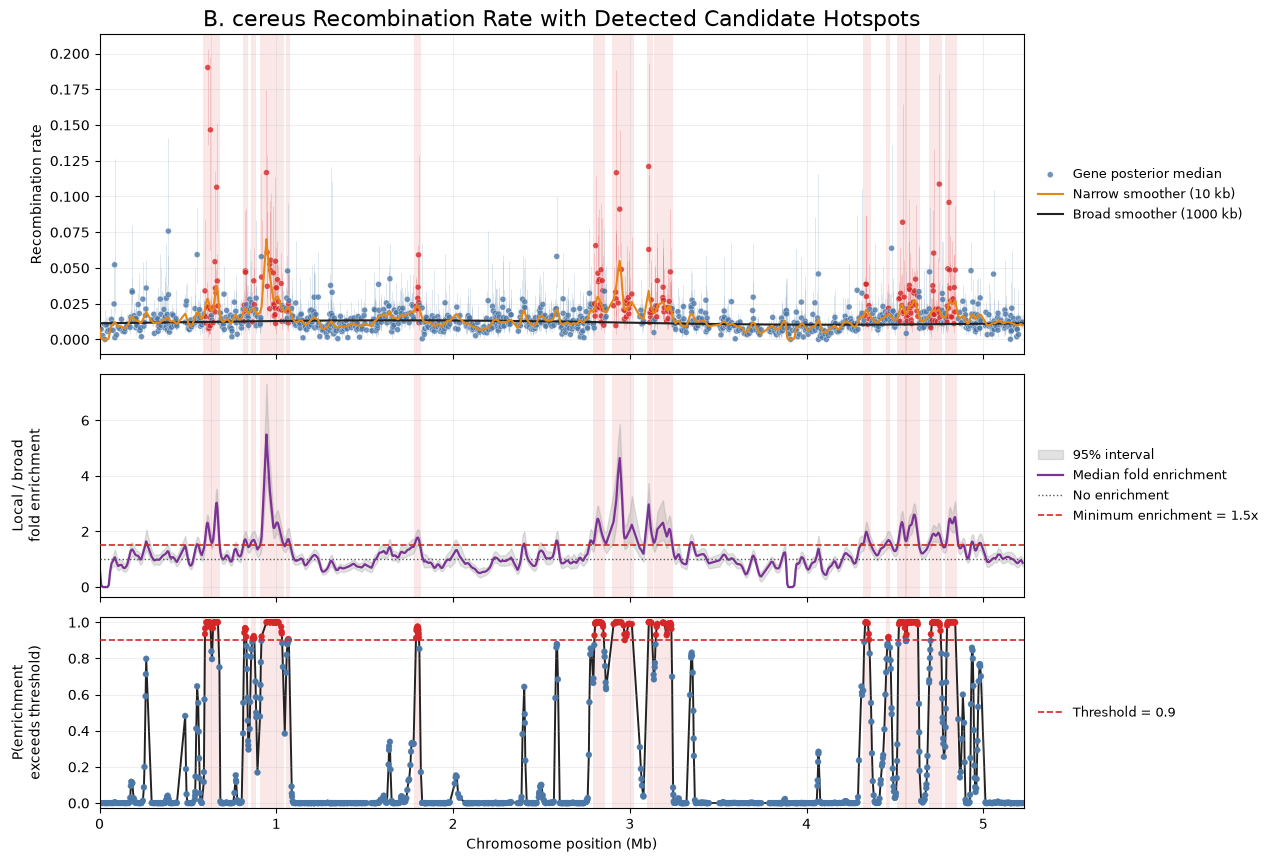

In [11]:
recomb = detect_hotspots(gene_starts, theta_post[:, :, 0], chromosome_length_bp,
                         min_fold_enrichment=1.5, **settings)
print(recomb.summary())

recomb.plot(
    rate_label="Recombination rate",
    title_text="B. cereus Recombination Rate with Detected Candidate Hotspots"
)
plt.show()

In [12]:
recomb_hotspots = recomb.to_dataframe()
recomb_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin
0,596779.0,633202.0,16,1.000,2.313814,0.9995,False
1,642338.0,672021.0,9,1.000,3.035686,1.0000,False
2,819132.0,831362.0,6,0.968,1.718169,0.9605,False
3,866656.0,877393.0,3,0.924,1.697599,0.9110,False
4,917005.0,1033471.0,25,1.000,5.488045,0.9990,False
5,1065265.0,1071176.0,3,0.907,1.724124,0.9040,False
6,1790666.0,1809442.0,9,0.976,1.780961,0.9570,False
7,2800266.0,2853730.0,19,1.000,2.456618,0.9960,False
8,2908540.0,3012194.0,19,1.000,4.641825,0.9900,False
9,3107059.0,3124701.0,8,1.000,2.973491,0.9995,False


Blocks in the first recombination hotspot:

In [13]:
segments = recomb.segment_gene_indices()
gene_info.iloc[segments[0]] if segments else "No hotspot detected"

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_raw,Start_pos_raw,End_pos_raw
Gene_ID,,,,,,,
174,638,596779,597416,True,658,596779,597436
164,6559,597542,604100,True,6590,597542,604131
179,2997,604113,607109,True,2998,604113,607110
183,2936,607196,610131,True,2957,607196,610152
201,2176,610354,612529,True,2178,610354,612531
107,619,612546,613164,True,619,612546,613164
176,2745,613424,616168,True,2769,613424,616192
137,917,616183,617099,True,922,616183,617104
169,1487,617120,618606,True,1488,617120,618607


### Mutation hotspots

Detected hotspot segments:
  none


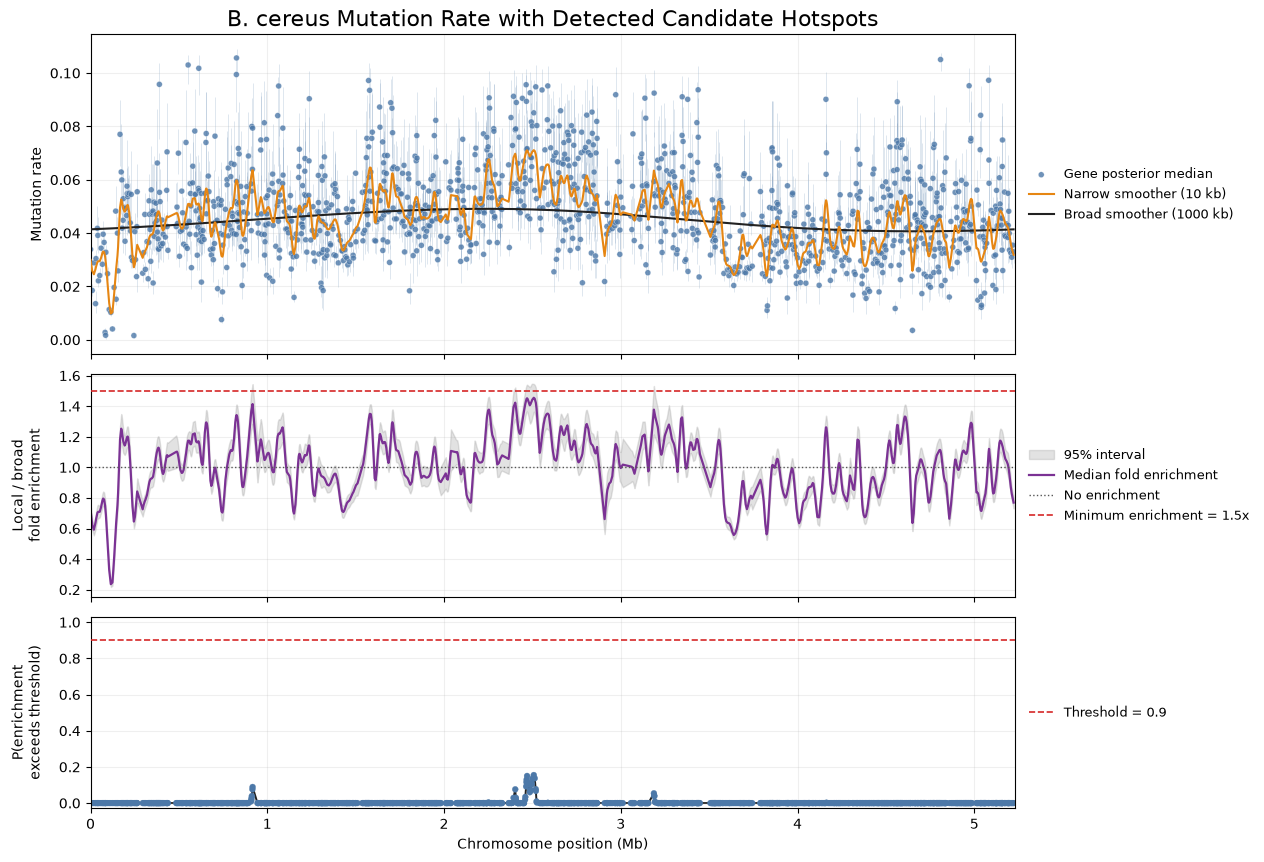

In [14]:
mutate = detect_hotspots(gene_starts, theta_post[:, :, 1], chromosome_length_bp,
                         min_fold_enrichment=1.5, **settings)
print(mutate.summary())

mutate.plot(
    rate_label="Mutation rate",
    title_text="B. cereus Mutation Rate with Detected Candidate Hotspots"
)
plt.show()

In [15]:
mutate_hotspots = mutate.to_dataframe()
mutate_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin


### Save the hotspot tables

One sheet per rate, as Table S4 of the paper.

In [16]:
save_hotspot_tables({"Recombination": recomb_hotspots, "Mutation": mutate_hotspots},
                    OUTPUT / "bacillus_hotspots.xlsx", overwrite=True)

WindowsPath('output/bacillus_hotspots.xlsx')